In [2]:
import numpy as np 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score,precision_score, recall_score, confusion_matrix ,ConfusionMatrixDisplay
import warnings
warnings.filterwarnings("ignore")

Matplotlib is building the font cache; this may take a moment.


In [3]:
df=pd.read_csv('data.csv')
df

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,M,69,1,0,0,1,1,0,1,0,0,0,0,0,0,1
1,M,74,0,1,1,1,0,0,0,1,1,1,0,0,0,1
2,F,59,1,1,1,0,1,0,1,0,1,0,0,1,0,1
3,M,63,0,0,0,1,1,1,1,1,0,1,1,0,0,0
4,F,63,1,0,1,1,1,1,1,0,1,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3394,F,56,1,1,1,0,0,0,1,1,0,0,0,0,1,1
3395,M,70,0,1,1,1,1,0,0,0,0,0,0,1,0,1
3396,M,58,0,1,1,1,1,1,0,0,0,0,1,1,0,0
3397,M,67,0,1,0,1,1,0,0,1,0,0,0,1,0,1


In [4]:
df['LUNG_CANCER'].value_counts()

LUNG_CANCER
1    1760
0    1639
Name: count, dtype: int64

In [5]:
df.columns

Index(['GENDER', 'AGE', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY',
       'PEER_PRESSURE', 'CHRONIC DISEASE', 'FATIGUE ', 'ALLERGY ', 'WHEEZING',
       'ALCOHOL CONSUMING', 'COUGHING', 'SHORTNESS OF BREATH',
       'SWALLOWING DIFFICULTY', 'CHEST PAIN', 'LUNG_CANCER'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3399 entries, 0 to 3398
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   GENDER                 3399 non-null   str  
 1   AGE                    3399 non-null   int64
 2   SMOKING                3399 non-null   int64
 3   YELLOW_FINGERS         3399 non-null   int64
 4   ANXIETY                3399 non-null   int64
 5   PEER_PRESSURE          3399 non-null   int64
 6   CHRONIC DISEASE        3399 non-null   int64
 7   FATIGUE                3399 non-null   int64
 8   ALLERGY                3399 non-null   int64
 9   WHEEZING               3399 non-null   int64
 10  ALCOHOL CONSUMING      3399 non-null   int64
 11  COUGHING               3399 non-null   int64
 12  SHORTNESS OF BREATH    3399 non-null   int64
 13  SWALLOWING DIFFICULTY  3399 non-null   int64
 14  CHEST PAIN             3399 non-null   int64
 15  LUNG_CANCER            3399 non-null   int64
dtyp

In [7]:
df['GENDER']=df['GENDER'].apply(lambda x:1 if x=='M' else 0)

In [8]:
df.isna().sum()

GENDER                   0
AGE                      0
SMOKING                  0
YELLOW_FINGERS           0
ANXIETY                  0
PEER_PRESSURE            0
CHRONIC DISEASE          0
FATIGUE                  0
ALLERGY                  0
WHEEZING                 0
ALCOHOL CONSUMING        0
COUGHING                 0
SHORTNESS OF BREATH      0
SWALLOWING DIFFICULTY    0
CHEST PAIN               0
LUNG_CANCER              0
dtype: int64

In [9]:
df

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,1,69,1,0,0,1,1,0,1,0,0,0,0,0,0,1
1,1,74,0,1,1,1,0,0,0,1,1,1,0,0,0,1
2,0,59,1,1,1,0,1,0,1,0,1,0,0,1,0,1
3,1,63,0,0,0,1,1,1,1,1,0,1,1,0,0,0
4,0,63,1,0,1,1,1,1,1,0,1,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3394,0,56,1,1,1,0,0,0,1,1,0,0,0,0,1,1
3395,1,70,0,1,1,1,1,0,0,0,0,0,0,1,0,1
3396,1,58,0,1,1,1,1,1,0,0,0,0,1,1,0,0
3397,1,67,0,1,0,1,1,0,0,1,0,0,0,1,0,1


In [10]:
X = df.drop(['LUNG_CANCER'], axis=1)
Y = df['LUNG_CANCER']

In [11]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,Y,test_size=0.2,random_state=70)

In [12]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(X_train, y_train)


GaussianNB()

In [13]:
y_pred = nb.predict(X_test)
precision = precision_score(y_test, y_pred, average='macro')
recall = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')
acc=accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")

Accuracy: 0.8794117647058823
Precision: 0.9063926940639269
Recall: 0.8734567901234568
F1 Score: 0.875924557858853


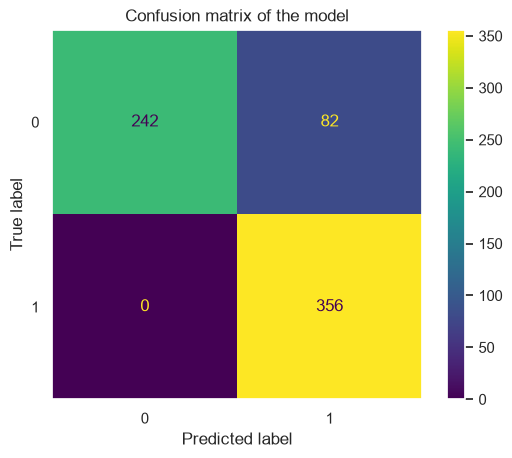

In [14]:
sns.set(rc = {'axes.grid':False})
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title('Confusion matrix of the model')
plt.show()

In [15]:
from sklearn.svm import SVC
svc = SVC()
svc.fit(X_train, y_train)

SVC()

In [16]:
y_pred = svc.predict(X_test)
precision = precision_score(y_test, y_pred, average='macro')
recall = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')
acc=accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")

Accuracy: 0.8485294117647059
Precision: 0.8733305607803477
Recall: 0.8424365376612568
F1 Score: 0.8440696833082875


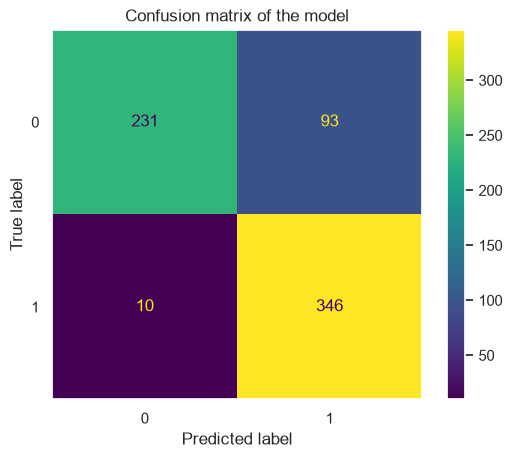

In [17]:
sns.set(rc = {'axes.grid':False})
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title('Confusion matrix of the model')
plt.show()

In [18]:
from sklearn.linear_model import Perceptron
perceptron_classifier = Perceptron()
perceptron_classifier.fit(X_train, y_train)

Perceptron()

In [19]:
y_pred = perceptron_classifier.predict(X_test)
precision = precision_score(y_test, y_pred, average='macro')
recall = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')
acc=accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")

Accuracy: 0.9544117647058824
Precision: 0.9563380281690141
Recall: 0.9564606741573034
F1 Score: 0.9544116661151949


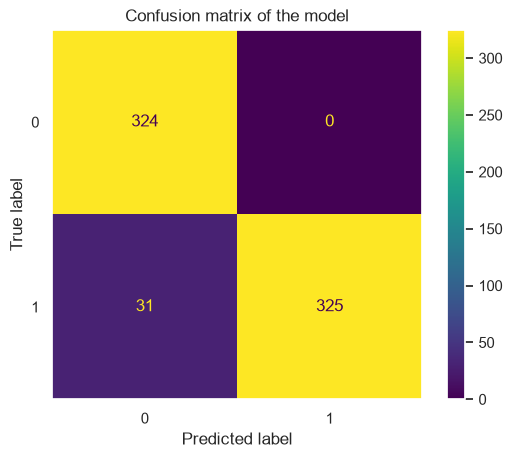

In [20]:
sns.set(rc = {'axes.grid':False})
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title('Confusion matrix of the model')
plt.show()

In [21]:
df

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,1,69,1,0,0,1,1,0,1,0,0,0,0,0,0,1
1,1,74,0,1,1,1,0,0,0,1,1,1,0,0,0,1
2,0,59,1,1,1,0,1,0,1,0,1,0,0,1,0,1
3,1,63,0,0,0,1,1,1,1,1,0,1,1,0,0,0
4,0,63,1,0,1,1,1,1,1,0,1,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3394,0,56,1,1,1,0,0,0,1,1,0,0,0,0,1,1
3395,1,70,0,1,1,1,1,0,0,0,0,0,0,1,0,1
3396,1,58,0,1,1,1,1,1,0,0,0,0,1,1,0,0
3397,1,67,0,1,0,1,1,0,0,1,0,0,0,1,0,1


In [22]:
Result= perceptron_classifier.predict(np.array([[1,69,1,0,0,1,1,0,1,0,0,0,0,0,0]]))

In [23]:
Result[0]

np.int64(1)

In [24]:
Result= perceptron_classifier.predict(np.array([[1,63,0,0,0,1,1,1,1,1,0,1,1,0,0]]))

In [25]:
Result[0]

np.int64(0)

In [26]:
import pickle
# Dump the trained perceptron classifier with Pickle
perceptron_filename = 'perceptron.pkl'
# Open the file to save as pkl file
perceptron_Model_pkl = open(perceptron_filename, 'wb')
pickle.dump(perceptron_classifier,perceptron_Model_pkl)
# Close the pickle instances
perceptron_Model_pkl.close()